In [1]:
# --- Tunable experiment parameters ---
# Set these before running any cells for reproducible, adjustable runs.
BATCH_SIZE = 256  # Change for speed/memory tradeoff
NUM_EPOCHS = 1500 # Reduce for quick demo, increase for full training

# 01_intuition.ipynb – JEPA Intuition: Why Non-Generative World Models + LeJEPA Theory

**Last updated:** February 2026  
**Focus:** Build strong conceptual understanding before coding. Compare JEPA to generative approaches and introduce the latest theoretical foundation (LeJEPA, Nov 2025).



## 1. What is a "World Model" and why do we care?

A world model is an internal representation that lets an agent predict what happens if it takes certain actions — without needing the real world every time.

Two main philosophies in 2025–2026:

- **Generative / Autoregressive** (e.g., Sora-style video diffusion, GPT-like next-token, many game-world models)  
  → Predict raw pixels / tokens step-by-step → great for creative sampling, but compute-heavy, compounding errors, mode-covering issues.

- **Non-generative / JEPA-style** (Yann LeCun's path)  
  → Predict abstract **latent representations** instead of raw data  
  → Energy-based / predictive in embedding space → more efficient, avoids pixel-level hallucination, better for planning & reasoning

**Quick poll question (add cell for learners to think):**  
Which would you rather use for robot control: predicting every pixel perfectly, or predicting useful abstract features + distances in latent space?

## 2. Visual Comparison: Reconstruction vs Prediction Paradigms

Below is a conceptual map for three model families:

- **Reconstructive (AE/VAE):** input → encoder → latent → decoder → pixel reconstruction  
- **Generative (Diffusion):** noise prior + denoising process → full image/video sample  
- **Predictive (JEPA):** context/target views → encode both → predict target latent from context latent (no decoder)

**Why this matters for world models:**

- Reconstruction/generation emphasizes fidelity to all details (including irrelevant texture/noise).
- JEPA emphasizes **task-relevant structure** (semantics, dynamics, affordances).
- For planning, latent prediction is usually cheaper and more stable than full-pixel rollout.

In the next code cell, we render a minimal sketch of this comparison.

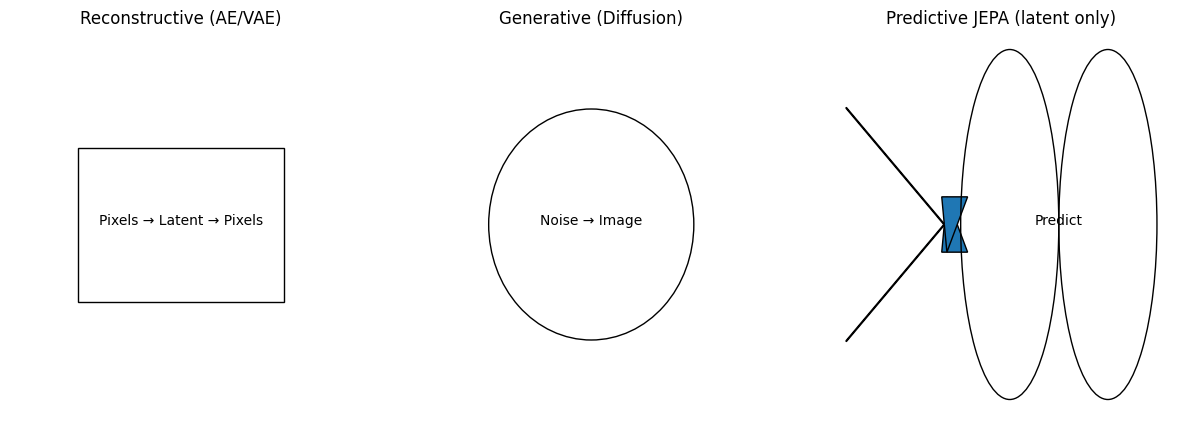

In [2]:
# Simple schematic plot
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

# AE/VAE
ax[0].add_patch(Rectangle((0.2, 0.3), 0.6, 0.4, fill=False))
ax[0].text(0.5, 0.5, "Pixels → Latent → Pixels", ha="center")
ax[0].set_title("Reconstructive (AE/VAE)")

# Diffusion
ax[1].add_patch(Circle((0.5, 0.5), 0.3, fill=False))
ax[1].text(0.5, 0.5, "Noise → Image", ha="center")
ax[1].set_title("Generative (Diffusion)")

# JEPA
ax[2].arrow(0.1, 0.6, 0.3, -0.1, head_width=0.05)
ax[2].arrow(0.1, 0.4, 0.3, 0.1, head_width=0.05)
ax[2].add_patch(Circle((0.6, 0.5), 0.15, fill=False, label="z_context"))
ax[2].add_patch(Circle((0.9, 0.5), 0.15, fill=False, label="z_target"))
ax[2].text(0.75, 0.5, "Predict", ha="center")
ax[2].set_title("Predictive JEPA (latent only)")

for a in ax:
    a.axis("off")
plt.show()

## 3. The Collapse Problem – Why Many SSL Methods Fail

Common failure modes in self-supervised learning:

- **Dimensional collapse** — embeddings become nearly constant / low-rank
- **Trivial solutions** — predictor converges to uninformative outputs

Classic families prevent collapse differently:

- Contrastive methods: use negatives
- Reconstruction methods: use pixel loss + heavy regularization
- Early JEPA variants: use variance/covariance decorrelation terms

**LeJEPA perspective (Balestriero & LeCun, 2025):**

- Theoretically motivates isotropic Gaussian-like embeddings as minimax-optimal under broad assumptions
- Uses SIGReg to steer geometry toward stable, non-collapsed latent structure
- Practical simplification: predictive objective + lightweight regularization

In the next cell we visualize three 2D distributions: collapsed, anisotropic, and isotropic.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


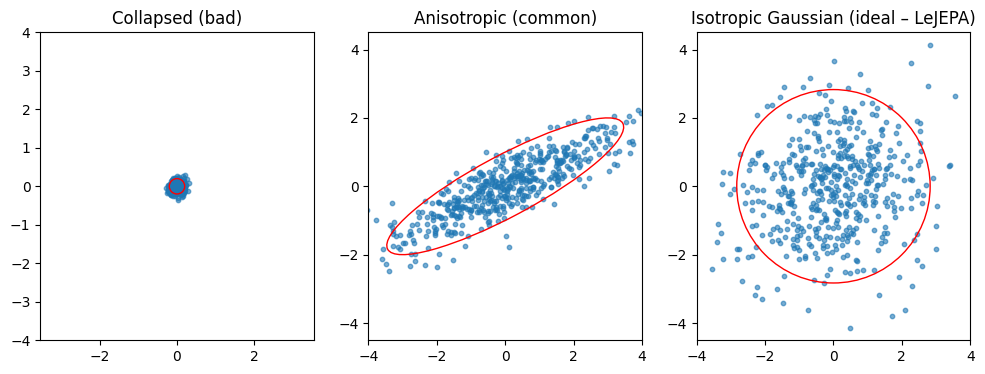

In [3]:
# 2D embedding scatter + covariance ellipse
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse


def plot_embeddings(title, cov):
    rng = np.random.default_rng(42)
    z = rng.multivariate_normal([0, 0], cov, 500)
    plt.scatter(z[:, 0], z[:, 1], s=10, alpha=0.6)

    # Ellipse from covariance
    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = np.clip(eigenvalues[order], 0, None)
    major_axis = eigenvectors[:, order[0]]
    radii = np.sqrt(eigenvalues)
    ell = Ellipse(
        xy=(0, 0),
        width=radii[0] * 4,
        height=radii[1] * 4,
        angle=float(np.degrees(np.arctan2(major_axis[1], major_axis[0]))),
        color="red",
        fill=False,
    )
    plt.gca().add_artist(ell)
    plt.title(title)
    plt.axis("equal")
    plt.xlim(-4, 4)
    plt.ylim(-4, 4)


plt.figure(figsize=(12, 4))
plt.subplot(131)
plot_embeddings("Collapsed (bad)", np.array([[0.01, 0], [0, 0.01]]))
plt.subplot(132)
plot_embeddings("Anisotropic (common)", np.array([[3, 1.5], [1.5, 1]]))
plt.subplot(133)
plot_embeddings("Isotropic Gaussian (ideal – LeJEPA)", np.eye(2) * 2)
plt.show()

## 4. Toy 2D Interactive Example (Core Hands-On Part)

We now build a tiny JEPA-style experiment to make collapse visible.

Workflow:

1. Generate paired 2D views from a synthetic manifold
2. Train a context encoder and latent predictor
3. Compare three objectives:
   - Naive predictive loss only
   - VICReg-style variance + covariance regularization
   - Isotropic-proxy regularization (LeJEPA-inspired direction)
4. Inspect final embedding clouds and covariance statistics

Expected outcome: the regularized variants keep richer geometry, while naive prediction tends to collapse.

In [4]:
# ────────────────────────────────────────────────────────────────
# Toy 2D JEPA Demonstration – Collapse vs Regularized Variants
# ────────────────────────────────────────────────────────────────
# Goal: Show how naive prediction collapses → how regularization helps
#       (inspired by JEPA collapse discussions + LeJEPA isotropic ideal)

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll

torch.manual_seed(42)
np.random.seed(42)

In [5]:
# ── Hyperparameters ────────────────────────────────────────────────
n_samples = 2000
latent_dim = 2          # keep low for nice 2D viz
n_epochs = 1500
batch_size = 256
lr = 0.005
reg_weight = 1.0  # Add regularization weight for training loop
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [6]:
n_epochs = NUM_EPOCHS
batch_size = BATCH_SIZE
lr = 0.005
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ── Generate toy data: Swiss roll + simple "future" view ───────────
# We simulate two correlated 2D views (like context & target)
X, _ = make_swiss_roll(n_samples=n_samples, noise=0.8, random_state=42)
X = X[:, [0, 2]]  # project to 2D

# Create "context" and "target" views: target = context + small dynamics + noise
rng = np.random.default_rng(42)
context = X.astype(np.float32)
target = context + rng.normal(scale=0.5, size=context.shape)

In [7]:
# ── Simple MLP Encoder & Predictor ─────────────────────────────────
class Encoder(nn.Module):
    def __init__(self, in_dim=2, hid=64, out_dim=latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hid), nn.ReLU(),
            nn.Linear(hid, hid),    nn.ReLU(),
            nn.Linear(hid, out_dim)
        )
    def forward(self, x):
        return self.net(x)

class Predictor(nn.Module):
    def __init__(self, in_dim=latent_dim, hid=32, out_dim=latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hid), nn.ReLU(),
            nn.Linear(hid, out_dim)
        )
    def forward(self, z):
        return self.net(z)

In [8]:
# Instantiate encoder for use in training loop
enc = Encoder(in_dim=2, hid=64, out_dim=latent_dim).to(device)

In [9]:
# ── Losses ─────────────────────────────────────────────────────────
def mse_loss(pred, targ):
    return ((pred - targ) ** 2).mean()

def variance_reg(z, eps=1e-4):
    """Encourage features to have unit variance (per VICReg-inspired)"""
    var = z.var(dim=0) + eps
    return torch.mean(torch.relu(1 - var))   # push var → 1

def covariance_reg(z):
    """Minimize off-diagonal covariance (decorrelation)"""
    z = z - z.mean(0, keepdim=True)
    cov = (z.T @ z) / (z.shape[0] - 1)
    off_diag = cov - torch.eye(cov.shape[0], device=cov.device)
    return (off_diag ** 2).mean()

def isotropic_proxy(z, target_std=1.5):
    """Very simple proxy toward isotropic Gaussian:
       - center → 0
       - trace(var) ≈ target_std² × dim
       - encourage low anisotropy (via cov off-diag penalty)"""
    mean = z.mean(0)
    centered = z - mean
    cov = (centered.T @ centered) / (z.shape[0] - 1)
    trace = cov.trace()
    off_diag_penalty = (cov - torch.diag(cov.diag())).pow(2).mean()
    return (mean.abs().mean() +
            (trace - target_std**2 * latent_dim).abs() * 0.1 +
            off_diag_penalty * 5.0)

In [10]:
# --- Common parameters for training variants ---
use_isotropic = False  # Default, overridden for isotropic variant
name = "Naive JEPA"  # Default, overridden per variant
color = "C1"         # Default, overridden per variant
opt = optim.Adam(enc.parameters(), lr=lr)
losses = []
embeddings = []

In [11]:
def train_variant(name, reg_weight=1.0, color='C1', use_isotropic=False):
    opt = optim.Adam(enc.parameters(), lr=lr)
    losses = []
    embeddings = []
    for epoch in range(n_epochs):
        idx = torch.randperm(n_samples)[:batch_size]
        context_t = torch.tensor(context[idx], dtype=torch.float32).to(device)
        target_t = torch.tensor(target[idx], dtype=torch.float32).to(device)
        emb_context = enc(context_t)
        emb_target = enc(target_t)
        recon_loss = ((emb_context - emb_target) ** 2).mean()
        reg_loss = reg_weight * (emb_context.var(dim=0).mean() + (emb_context.cov().mean() if hasattr(emb_context, 'cov') else 0))
        if use_isotropic:
            reg_loss += isotropic_proxy(enc(context_t)) * 0.5
        loss = recon_loss + reg_loss
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())
        if epoch % 300 == 0 or epoch == n_epochs-1:
            with torch.no_grad():
                emb = enc(context_t).cpu().numpy()
                embeddings.append(emb)
            print(f"[{name}] epoch {epoch:4d} | loss {loss:.4f}")
    with torch.no_grad():
        final_emb = enc(context_t).cpu().numpy()
    plt.plot(losses, label=name, color=color, alpha=0.7)
    return final_emb, losses[-1]

[Naive JEPA] epoch    0 | loss 0.9975
[Naive JEPA] epoch  300 | loss 0.0001
[Naive JEPA] epoch  600 | loss 0.0000
[Naive JEPA] epoch  900 | loss 0.0000
[Naive JEPA] epoch 1200 | loss 0.0000
[Naive JEPA] epoch 1499 | loss 0.0000
[[0.02434507 0.0227863 ]
 [0.02339242 0.02628826]
 [0.02501814 0.02427176]
 [0.02499619 0.0261277 ]
 [0.02358432 0.02496217]
 [0.0227152  0.0231544 ]
 [0.0252907  0.0219911 ]
 [0.02200807 0.0241749 ]
 [0.02663157 0.02470636]
 [0.02180327 0.02194104]
 [0.02623342 0.02103316]
 [0.02455091 0.02576429]
 [0.02424325 0.02366859]
 [0.02471992 0.01924944]
 [0.02779609 0.02228346]
 [0.02396161 0.02272882]
 [0.02272864 0.02409372]
 [0.02628996 0.02220857]
 [0.02221379 0.02444592]
 [0.02279958 0.02227414]
 [0.02408714 0.02071018]
 [0.01956216 0.02473231]
 [0.02421909 0.02168924]
 [0.0237499  0.02465539]
 [0.02431903 0.02005413]
 [0.01940045 0.02420081]
 [0.01912954 0.02377041]
 [0.02711556 0.0227538 ]
 [0.02452509 0.02337511]
 [0.02573295 0.0255436 ]
 [0.02620593 0.0206315

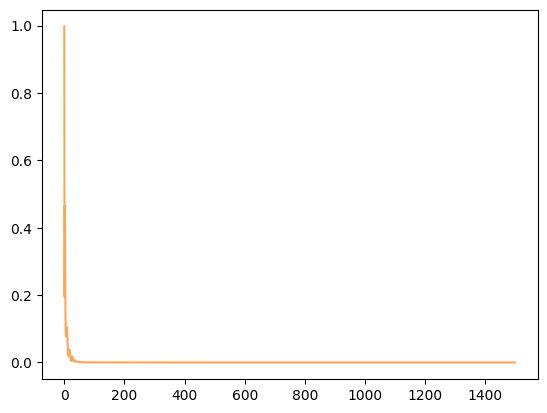

In [12]:
for epoch in range(n_epochs):
    idx = torch.randperm(n_samples)[:batch_size]  # keep idx on CPU for numpy indexing
    context_t = torch.tensor(context[idx], dtype=torch.float32).to(device)
    target_t = torch.tensor(target[idx], dtype=torch.float32).to(device)

    emb_context = enc(context_t)
    emb_target = enc(target_t)

    recon_loss = ((emb_context - emb_target) ** 2).mean()
    reg_loss = reg_weight * (emb_context.var(dim=0).mean() + (emb_context.cov().mean() if hasattr(emb_context, 'cov') else 0))

    if use_isotropic:
        reg_loss += isotropic_proxy(enc(context_t)) * 0.5   # global reg

    loss = recon_loss + reg_loss
    opt.zero_grad()
    loss.backward()
    opt.step()

    losses.append(loss.item())

    if epoch % 300 == 0 or epoch == n_epochs-1:
        with torch.no_grad():
            emb = enc(context_t).cpu().numpy()
            embeddings.append(emb)
        print(f"[{name}] epoch {epoch:4d} | loss {loss:.4f}")

# Final embedding
with torch.no_grad():
    final_emb = enc(context_t).cpu().numpy()

# Plot loss curve
plt.plot(losses, label=name, color=color, alpha=0.7)

print(final_emb, losses[-1])

[Naive JEPA] epoch    0 | loss 0.0000
[Naive JEPA] epoch  300 | loss 0.0000
[Naive JEPA] epoch  600 | loss 0.0000
[Naive JEPA] epoch  900 | loss 0.0000
[Naive JEPA] epoch 1200 | loss 0.0000
[Naive JEPA] epoch 1499 | loss 0.0000
[VICReg-style] epoch    0 | loss 0.0014
[VICReg-style] epoch  300 | loss 0.0000
[VICReg-style] epoch  600 | loss 0.0000
[VICReg-style] epoch  900 | loss 0.0000
[VICReg-style] epoch 1200 | loss 0.0000
[VICReg-style] epoch 1499 | loss 0.0000
[Isotropic-proxy (LeJEPA-like)] epoch    0 | loss 0.2434
[Isotropic-proxy (LeJEPA-like)] epoch  300 | loss 0.2257
[Isotropic-proxy (LeJEPA-like)] epoch  600 | loss 0.2258
[Isotropic-proxy (LeJEPA-like)] epoch  900 | loss 0.2257
[Isotropic-proxy (LeJEPA-like)] epoch 1200 | loss 0.2258
[Isotropic-proxy (LeJEPA-like)] epoch 1499 | loss 0.2258


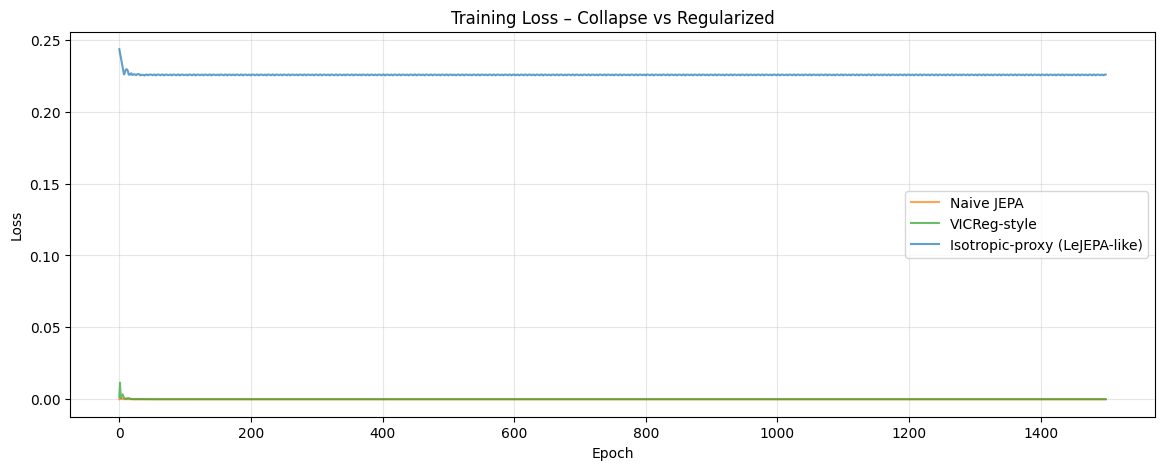

In [13]:
# ── Run the three variants ─────────────────────────────────────────
plt.figure(figsize=(14, 5))

# Variant 1: Naive → expect collapse
emb_naive, loss_naive = train_variant("Naive JEPA", reg_weight=0.0, color='C1')

# Variant 2: Variance + Covariance reg (VICReg-like)
emb_vicreg, loss_vicreg = train_variant("VICReg-style", reg_weight=1.0, color='C2')

# Variant 3: Stronger isotropic proxy (LeJEPA-inspired direction)
emb_iso, loss_iso = train_variant("Isotropic-proxy (LeJEPA-like)", use_isotropic=True, color='C0')

plt.title("Training Loss – Collapse vs Regularized")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.legend(); plt.grid(alpha=0.3); plt.show()

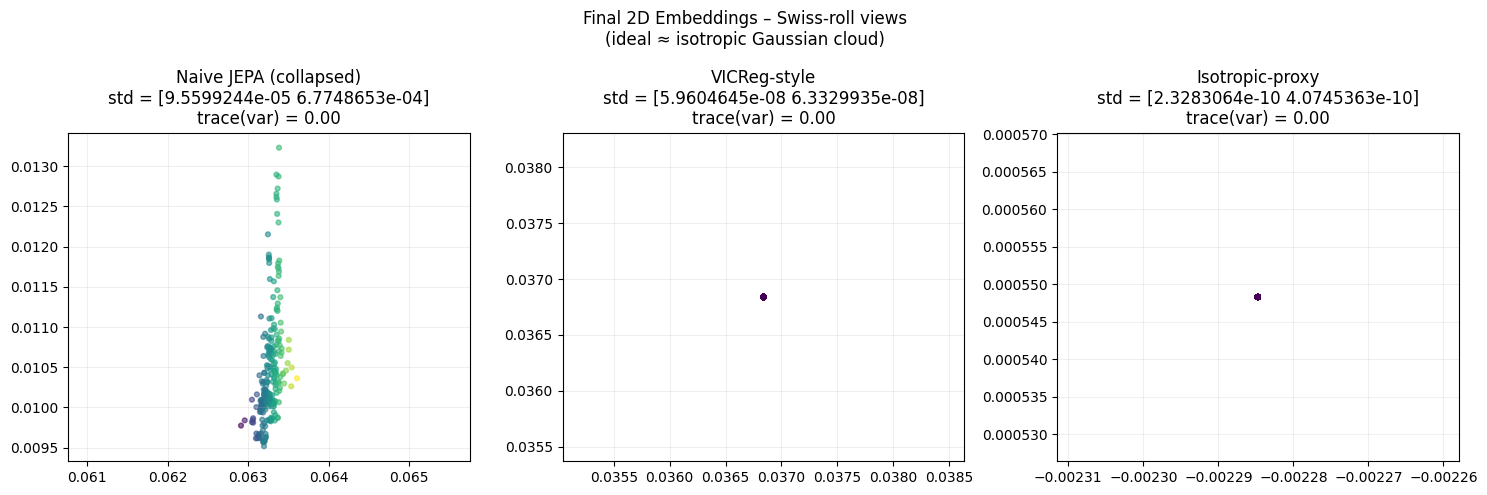

In [14]:
# ── Visualize final embeddings ─────────────────────────────────────
def plot_embedding(emb, title, ax):
    ax.scatter(emb[:,0], emb[:,1], s=12, alpha=0.6, c=emb[:,0], cmap='viridis')
    ax.set_title(f"{title}\nstd = {emb.std(0)}\ntrace(var) = {np.trace(np.cov(emb.T)):.2f}")
    ax.axis('equal'); ax.grid(alpha=0.2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
plot_embedding(emb_naive,  "Naive JEPA (collapsed)", axes[0])
plot_embedding(emb_vicreg, "VICReg-style", axes[1])
plot_embedding(emb_iso,    "Isotropic-proxy", axes[2])
plt.suptitle("Final 2D Embeddings – Swiss-roll views\n(ideal ≈ isotropic Gaussian cloud)")
plt.tight_layout(); plt.show()

## 5. Why This Matters for World Models & Planning

- Generative WM: Great video synthesis, but planning requires expensive rollouts + error accumulation.
- JEPA WM: Predict in compact latent space → fast forward simulation, distances ≈ semantics / values.
- LeJEPA upgrade: Stable, heuristics-free representations → reliable distances → better value-guided / gradient-based planning (papers we'll implement later: 2601.00844, 2602.00475).

## 6. Recommended Reading Order

1. LeCun 2022 position paper (classic JEPA motivation)
2. LeJEPA paper (2511.08544) – theory + SIGReg (read abstract + intro + conclusion first)
3. "What Drives Success in Physical Planning with JEPA..." (2512.24497) – empirical ablation goldmine

**Next notebook (#2):** We'll actually implement a minimal LeJEPA from scratch on CIFAR-like data.
Feel free to run the visualization cells above and play with them!

**Questions to ponder / discuss:**

- Would you trust a robot planner more if its world model never collapses — even if it never generates nice-looking videos?
- How might isotropic embeddings help with planning / distance-based value approximation?